# Manual retrieval compare — BM25 vs Dense vs gold, by item id

Look up an item **by its `id`** (not list index), see its question, options,
GT, and image, write a retrieval query **yourself**, and run it against
**both** `BM25Retriever` and `DenseRetriever` (BGE-M3) — side by side,
against the item's gold chunk ids.

No PERCEIVE/FORMULATE/ASSESS/SELECT, no LLM anywhere — this is purely about
comparing the two retrievers' raw behavior on a query you write by hand.

**Kernel**: `traffic` — has the BM25 (pyserini + bundled Java 21) and Dense
(FlagEmbedding/BGE-M3, needs a GPU node) stacks both working. The corpus's
dense embeddings are already cached under `index/dense/`, so `DenseRetriever`
init only needs to load the BGE-M3 model itself, not re-encode the corpus.


In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "agent").exists():
    ROOT = ROOT.parent  # running from notebooks/, repo root is one level up
assert (ROOT / "agent").exists(), f"can't find the agent/ package from {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from PIL import Image

from agent.cli import resolve_image_path
from agent.corpus import Corpus
from agent.resolve import CitationIndex
from agent.retrieval.bm25 import DEFAULT_INDEX_DIR, BM25Retriever
from agent.retrieval.dense import DEFAULT_CACHE_DIR, DEFAULT_MODEL_NAME, DenseRetriever
from agent.schemas import RetrievalQuery


In [2]:
import os 
os.environ["CUDA_VISIBLE_DEVICES"] = "6"  # disable GPU for this test

NameError: name 'records_by_id' is not defined

## Config — edit this cell, then run everything below

In [3]:
# --- data ---
DATA_PATH = ROOT / "law.json"
CORPUS_PATH = ROOT / "law_db.json"
DATA_ROOT = ROOT

# --- BM25 ---
BM25_INDEX_DIR = DEFAULT_INDEX_DIR
BM25_K1, BM25_B = 0.9, 0.4

# --- Dense (BGE-M3) ---
DENSE_MODEL_NAME = DEFAULT_MODEL_NAME
DENSE_CACHE_DIR = DEFAULT_CACHE_DIR
DENSE_DEVICE = "cuda"  # "cpu" works too, just slower to load/encode queries

K = 5          # how many results to show PER RETRIEVER PER QUERY
AS_OF = None   # effective_date filter, e.g. "2025-01-01"


In [4]:
records = json.loads(DATA_PATH.read_text(encoding="utf-8"))
records_by_id = {rec.get("id"): rec for rec in records}
corpus = Corpus.load(CORPUS_PATH)
citation_index = CitationIndex.from_file(CORPUS_PATH)
print(f"{len(records)} questions | corpus: {len(corpus)} chunks (v{corpus.version})")


2414 questions | corpus: 1071 chunks (v50831f77beff)


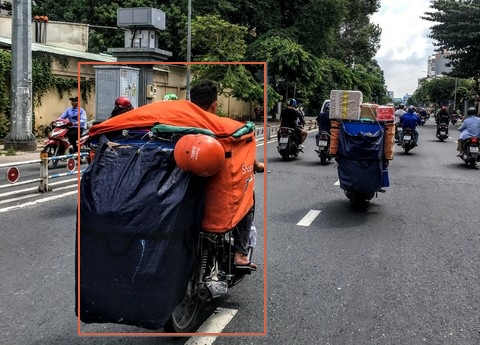

item_id=8  type_image=cong_kenh
Q: Nếu hành vi trong ảnh của người điều khiển xe máy được khoanh đỏ ở gần giữa phía bên trái ảnh gây tai nạn giao thông thì người này bị xử lý như thế nào?

A. Phạt từ 10.400.000 đồng đến 14.600.000 đồng và bị tước quyền sử dụng giấy phép lái xe từ 01 tháng đến 03 tháng.
B. Phạt tổng cộng từ 10.400.000 đồng đến 14.600.000 đồng, bị trừ 10 điểm giấy phép lái xe và không bị tước quyền sử dụng giấy phép lái xe. <- GT
C. Phạt từ 10.000.000 đồng đến 14.000.000 đồng và bị trừ 02 điểm giấy phép lái xe.
D. Phạt từ 600.000 đồng đến 800.000 đồng và không bị trừ điểm giấy phép lái xe.

gold chunk ids (4): ['ND_168_2024_D7_K10', 'ND_168_2024_D7_K13', 'ND_168_2024_D7_K2', 'ND_168_2024_D7_K3']

[ND_168_2024_D7_K10] Khoản 10, Điều 7, 168/2024/NĐ-CP
Văn bản: Nghị định xử phạt vi phạm hành chính về trật tự, an toàn giao thông đường bộ. Trích dẫn: Khoản 10, Điều 7, 168/2024/NĐ-CP. Ngữ cảnh: CHƯƠNG II | MỤC 1. VI PHẠM QUY TẮC GIAO THÔNG ĐƯỜNG BỘ. Tên điều hoặc mục: Xử phạt,

In [5]:
ITEM_ID = 8  # <-- set the item id you want to inspect

rec = records_by_id.get(ITEM_ID)
assert rec is not None, f"no item with id={ITEM_ID!r} in {DATA_PATH}"

gold_ids = citation_index.resolve_set(rec.get("law", []))
image_path = resolve_image_path(rec["image"], DATA_ROOT)

display(Image.open(image_path))
print(f"item_id={rec.get('id')}  type_image={rec.get('type_image')}")
print(f"Q: {rec['question']}\n")
for L in ("A", "B", "C", "D"):
    marker = " <- GT" if rec.get("GT") == L else ""
    print(f"{L}. {rec[L]}{marker}")
print(f"\ngold chunk ids ({len(gold_ids)}): {sorted(gold_ids)}")
for cid in sorted(gold_ids):
    chunk = corpus.by_id.get(cid)
    if chunk:
        print(f"\n[{cid}] {chunk.title}")
        print(chunk.text)


In [6]:
bm25_retriever = BM25Retriever(index_dir=BM25_INDEX_DIR, k1=BM25_K1, b=BM25_B)
print("BM25 ready")


/home/dangle/miniconda3/envs/traffic/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BM25 ready


Jul 25, 2026 6:07:10 PM org.apache.lucene.store.MemorySegmentIndexInputProvider <init>
INFO: Using MemorySegmentIndexInput with Java 21; to disable start with -Dorg.apache.lucene.store.MMapDirectory.enableMemorySegments=false


In [7]:
# Loads the BGE-M3 model (needs a GPU node for DENSE_DEVICE="cuda") and
# either loads the cached corpus embeddings (index/dense/) or, on a cache
# miss (corpus changed), re-encodes the whole corpus once.
dense_retriever = DenseRetriever(corpus, model_name=DENSE_MODEL_NAME, device=DENSE_DEVICE, cache_dir=DENSE_CACHE_DIR)
print("Dense ready")


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7454.52it/s]

Dense ready


## Step 1 — look up an item by id

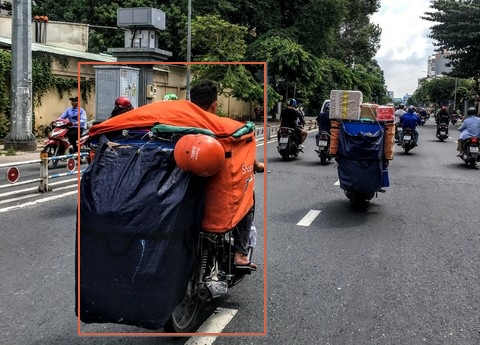

item_id=5  type_image=cong_kenh
Q: Người điều khiển xe máy được khoanh đỏ cam ở gần giữa phía bên trái ảnh có hành vi nào sau đây?

A. Đi đúng quy định và bảo đảm an toàn.
B. Không đội mũ bảo hiểm và chở vật cồng kềnh. <- GT
C. Không chấp hành tín hiệu đèn giao thông và đi ngược chiều.
D. Dừng xe trên phần đường dành cho người đi bộ.

gold chunk ids (4): ['LUAT_36_2024_D33_K2', 'LUAT_36_2024_D33_K3', 'ND_168_2024_D7_K2', 'ND_168_2024_D7_K3']

[LUAT_36_2024_D33_K2] Khoản 2, Điều 33, 36/2024/QH15
Văn bản: Luật Trật tự, an toàn giao thông đường bộ. Trích dẫn: Khoản 2, Điều 33, 36/2024/QH15. Ngữ cảnh: CHƯƠNG II. Tên điều hoặc mục: Người lái xe, người được chở, hàng hóa xếp trên xe mô tô, xe gắn máy. Phương tiện: xe_mo_to, xe_o_to. Nội dung: 2. Người lái xe, người được chở trên xe mô tô hai bánh, xe mô tô ba bánh, xe gắn máy phải đội mũ bảo hiểm theo đúng quy chuẩn kỹ thuật quốc gia và cài quai đúng quy cách.

[LUAT_36_2024_D33_K3] Khoản 3, Điều 33, 36/2024/QH15
Văn bản: Luật Trật tự, an to

In [ ]:
ITEM_ID = 6  # <-- set the item id you want to inspect

rec = records_by_id.get(ITEM_ID)
assert rec is not None, f"no item with id={ITEM_ID!r} in {DATA_PATH}"

gold_ids = citation_index.resolve_set(rec.get("law", []))
image_path = resolve_image_path(rec["image"], DATA_ROOT)

display(Image.open(image_path))
print(f"item_id={rec.get('id')}  type_image={rec.get('type_image')}")
print(f"Q: {rec['question']}\n")
for L in ("A", "B", "C", "D"):
    marker = " <- GT" if rec.get("GT") == L else ""
    print(f"{L}. {rec[L]}{marker}")
print(f"\ngold chunk ids ({len(gold_ids)}): {sorted(gold_ids)}")
for cid in sorted(gold_ids):
    chunk = corpus.by_id.get(cid)
    if chunk:
        print(f"\n[{cid}] {chunk.title}")
        print(chunk.text)


## Step 2 — write your own query

One or more raw query strings — no PERCEIVE/FORMULATE involved, this is
exactly what gets sent to `retriever.retrieve()`. `vehicle_filter`/`doc_boost`
are optional hard filters/score boosts (see `agent/retrieval/filters.py`);
leave them empty (`[]`) to search the whole corpus unfiltered.


In [12]:
MY_QUERIES = [
    "xe mô tô không đội mũ bảo hiểm trừ điểm",
    # add more query strings here to compare how each one retrieves
]

MY_VEHICLE_FILTER: list[str] = []   # e.g. ["xe_mo_to"] -- see agent.vehicle.CORPUS_VEHICLE_TERMS for valid slugs
MY_DOC_BOOST: list[str] = []        # e.g. ["ND_168_2024"]

queries = [RetrievalQuery(text=t, vehicle_filter=MY_VEHICLE_FILTER, doc_boost=MY_DOC_BOOST) for t in MY_QUERIES]
for q in queries:
    print(q)


text='xe mô tô không đội mũ bảo hiểm trừ điểm' vehicle_filter=[] doc_boost=[]


## Step 3 — run BM25 and Dense on the same query, side by side

In [ ]:
def run_retriever(retriever, name: str) -> pd.DataFrame:
    rows = []
    for q in queries:
        for rank, chunk in enumerate(retriever.retrieve(q, corpus, K, AS_OF), start=1):
            rows.append({
                "retriever": name,
                "query": q.text,
                "rank": rank,
                "chunk_id": chunk.chunk_id,
                "score": chunk.score,
                "is_gold": chunk.chunk_id in gold_ids,
            })
    return pd.DataFrame(rows)


bm25_df = run_retriever(bm25_retriever, "bm25")
dense_df = run_retriever(dense_retriever, "dense")
results_df = pd.concat([bm25_df, dense_df], ignore_index=True)
results_df


,retriever,query,rank,chunk_id,score,is_gold
0,bm25,người điều khiển xe máy không đội mũ bảo hiểm ...,1,ND_168_2024_D7_K2,10.816200,True
1,bm25,người điều khiển xe máy không đội mũ bảo hiểm ...,2,ND_168_2024_D9_K4,10.640300,False
2,bm25,người điều khiển xe máy không đội mũ bảo hiểm ...,3,ND_168_2024_D12_K5,8.911000,False
3,bm25,người điều khiển xe máy không đội mũ bảo hiểm ...,4,LUAT_36_2024_D31_K3,7.433100,False
4,bm25,người điều khiển xe máy không đội mũ bảo hiểm ...,5,LUAT_36_2024_D33_K2,6.571200,False
5,dense,người điều khiển xe máy không đội mũ bảo hiểm ...,1,ND_168_2024_D18_K2,0.664062,False
6,dense,người điều khiển xe máy không đội mũ bảo hiểm ...,2,ND_168_2024_D19_K1,0.655273,False
7,dense,người điều khiển xe máy không đội mũ bảo hiểm ...,3,ND_168_2024_D13_K1,0.652344,False
8,dense,người điều khiển xe máy không đội mũ bảo hiểm ...,4,ND_168_2024_D14_K1,0.648438,False
9,dense,người điều khiển xe máy không đội mũ bảo hiểm ...,5,ND_168_2024_D14_K2,0.641602,False


In [ ]:
# Per-retriever recall@K against gold (union across all MY_QUERIES).
for name, df in (("bm25", bm25_df), ("dense", dense_df)):
    retrieved_ids = set(df["chunk_id"])
    overlap = retrieved_ids & gold_ids
    recall = len(overlap) / len(gold_ids) if gold_ids else None
    print(f"{name}: retrieved={len(retrieved_ids)}  overlap={len(overlap)}  recall={recall}")
    print(f"  hit gold ids: {sorted(overlap)}")
    print(f"  missed gold ids: {sorted(gold_ids - retrieved_ids)}\n")


bm25: retrieved=5  overlap=1  recall=0.25
  hit gold ids: ['ND_168_2024_D7_K2']
  missed gold ids: ['ND_168_2024_D7_K10', 'ND_168_2024_D7_K13', 'ND_168_2024_D7_K3']

dense: retrieved=5  overlap=0  recall=0.0
  hit gold ids: []
  missed gold ids: ['ND_168_2024_D7_K10', 'ND_168_2024_D7_K13', 'ND_168_2024_D7_K2', 'ND_168_2024_D7_K3']



In [ ]:
# Chunks BOTH retrievers agree on vs. chunks only one of them found.
bm25_ids = set(bm25_df["chunk_id"])
dense_ids = set(dense_df["chunk_id"])
print(f"agreed (both retrievers): {sorted(bm25_ids & dense_ids)}")
print(f"bm25 only:                {sorted(bm25_ids - dense_ids)}")
print(f"dense only:               {sorted(dense_ids - bm25_ids)}")


## Step 4 (optional) — read full chunk text for anything retrieved